# California housing price prediction
Datheon · Machine Learning & Data Science Internship · Task 2

Predict median house values for California census block groups. Compare ordinary least squares (OLS), Ridge (L2), and Lasso (L1) on the same holdout.

This notebook uses the [California Housing CSV distributed with Hands-On Machine Learning](https://github.com/ageron/handson-ml2/tree/master/datasets/housing). It includes missing bedroom totals and an ocean proximity category. In Colab choose **Runtime → Run all**. For a local environment install pandas, NumPy, seaborn, matplotlib, and scikit-learn ≥ 1.4. The code downloads the CSV if no local copy is present.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

source = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
local_csv = Path("housing.csv")
housing = pd.read_csv(local_csv if local_csv.is_file() else source)
X = housing.drop(columns="median_house_value")
y = housing["median_house_value"]
seed = 17
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=seed
)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")
print(f"Missing bedroom totals | Full: {X.total_bedrooms.isna().sum()} | Train: {X_train.total_bedrooms.isna().sum()} | Test: {X_test.total_bedrooms.isna().sum()}")


Train: 16,512 | Test: 4,128
Missing bedroom totals | Full: 207 | Train: 163 | Test: 44


## Inspect correlations and engineer features

Room count, bedroom count, population and household count all reflect block group size. Keep households as a size measure and replace the other totals with ratios. The heatmaps compare numeric correlations before and after these replacements. Each heatmap uses training medians for its visualization only.

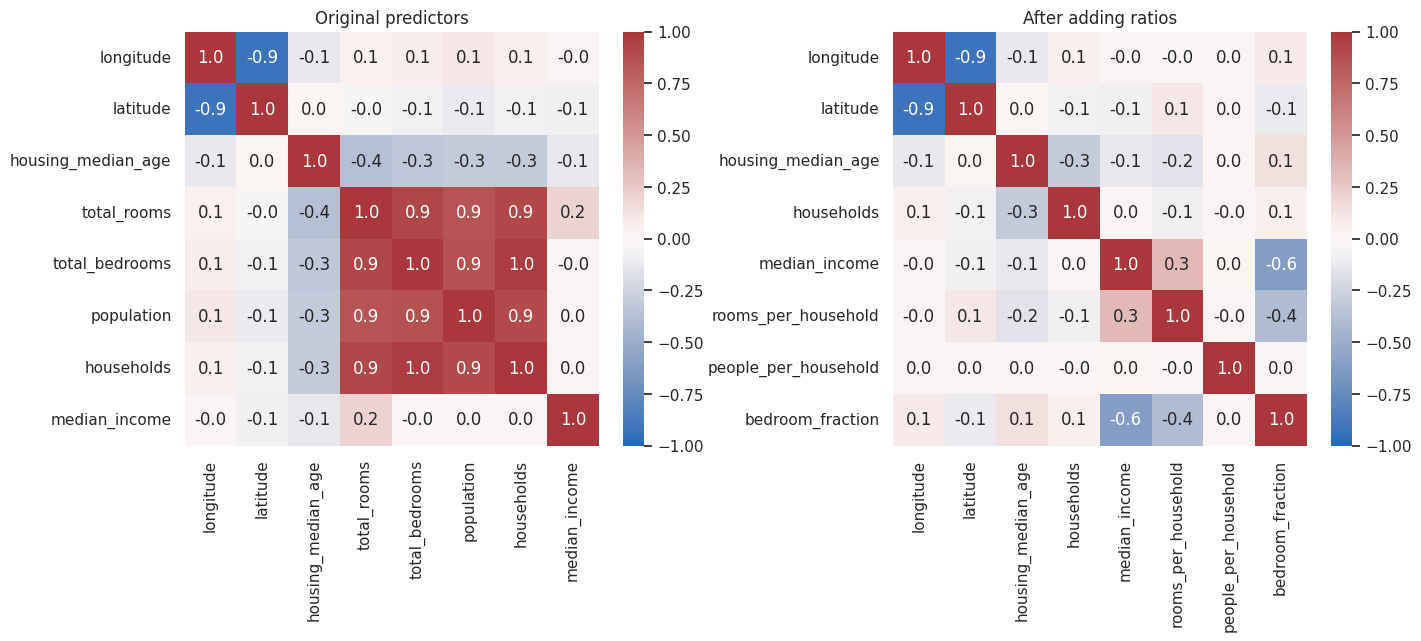

In [2]:
def use_ratios(frame):
    features = frame.copy()
    households = features["households"].replace(0, np.nan)
    rooms = features["total_rooms"].replace(0, np.nan)
    features["rooms_per_household"] = features["total_rooms"] / households
    features["people_per_household"] = features["population"] / households
    features["bedroom_fraction"] = features["total_bedrooms"] / rooms
    return features.drop(columns=["total_rooms", "total_bedrooms", "population"])

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6.3), layout="constrained")
for ax, frame, title in zip(
    axes, [X_train, use_ratios(X_train)], ["Original predictors", "After adding ratios"]
):
    numeric = frame.select_dtypes(include="number")
    corr = numeric.fillna(numeric.median()).corr()
    sns.heatmap(corr, vmin=-1, vmax=1, cmap="vlag", annot=True,
                fmt=".1f", square=True, ax=ax)
    ax.set_title(title)
plt.show()

## Preprocess and tune the models

Impute numeric predictors using medians and standardize them. Then multiply centered predictors to create income × rooms per household and latitude × longitude interactions. Rescale to give the numeric main effects and interactions comparable units for regularization. For ocean proximity, impute the most frequent category if needed and one-hot encode with a reference category to avoid dummy-variable collinearity.

All preprocessing is fitted within the pipeline for each training fold. Grid search selects each model’s alpha by five-fold validation RMSE. Ridge shrinks coefficients and Lasso can set some coefficients to zero.

In [3]:
numeric_columns = use_ratios(X_train).select_dtypes(include="number").columns.to_list()

def interactions(values):
    income = values[:, numeric_columns.index("median_income")]
    rooms = values[:, numeric_columns.index("rooms_per_household")]
    latitude = values[:, numeric_columns.index("latitude")]
    longitude = values[:, numeric_columns.index("longitude")]
    return np.column_stack([values, income * rooms, latitude * longitude])

preprocess = ColumnTransformer([
    ("numeric", make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(),
        FunctionTransformer(interactions), StandardScaler()
    ), numeric_columns),
    ("category", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
    ), ["ocean_proximity"]),
])

def make_model(estimator):
    return make_pipeline(FunctionTransformer(use_ratios), clone(preprocess), estimator)

models = {"OLS": make_model(LinearRegression()).fit(X_train, y_train)}
alphas = {"OLS": np.nan}
cv = KFold(n_splits=5, shuffle=True, random_state=seed)
for name, estimator, grid in [
    ("Ridge", Ridge(), np.logspace(-2, 4, 13)),
    ("Lasso", Lasso(max_iter=20000), np.logspace(0, 4, 9)),
]:
    step = name.lower()
    search = GridSearchCV(make_model(estimator), {f"{step}__alpha": grid},
                          scoring="neg_root_mean_squared_error", cv=cv, error_score="raise")
    search.fit(X_train, y_train)
    models[name] = search.best_estimator_
    alphas[name] = search.best_params_[f"{step}__alpha"]
    print(f"{name} | alpha: {alphas[name]:g} | validation RMSE: {-search.best_score_:,.2f} USD")

Ridge | alpha: 0.0316228 | validation RMSE: 70,159.76 USD
Lasso | alpha: 1 | validation RMSE: 70,159.69 USD


## Compare predictions on the test set

RMSE and MAE are in US dollars. RMSE penalizes large misses more heavily. MAE measures the average absolute miss. Lower errors and higher R² indicate better performance on this holdout.

In [4]:
predictions = {name: model.predict(X_test) for name, model in models.items()}
results = pd.DataFrame([
    {"Model": name, "Alpha": alphas[name],
     "RMSE (USD)": root_mean_squared_error(y_test, pred),
     "MAE (USD)": mean_absolute_error(y_test, pred),
     "R²": r2_score(y_test, pred)}
    for name, pred in predictions.items()
]).set_index("Model").sort_values("RMSE (USD)")
print(results.to_string(float_format=lambda value: f"{value:,.3f}", na_rep="—"))

       Alpha  RMSE (USD)  MAE (USD)    R²
Model                                    
OLS        —  69,989.878 50,692.615 0.625
Ridge  0.032  69,990.349 50,692.949 0.625
Lasso  1.000  69,991.571 50,693.702 0.625


## Predicted vs. actual and residual distributions

The dashed diagonal represents exact predictions. The vertical band at $500,001 reflects the dataset’s price cap. Residuals are actual minus predicted, so positive residuals indicate underprediction.

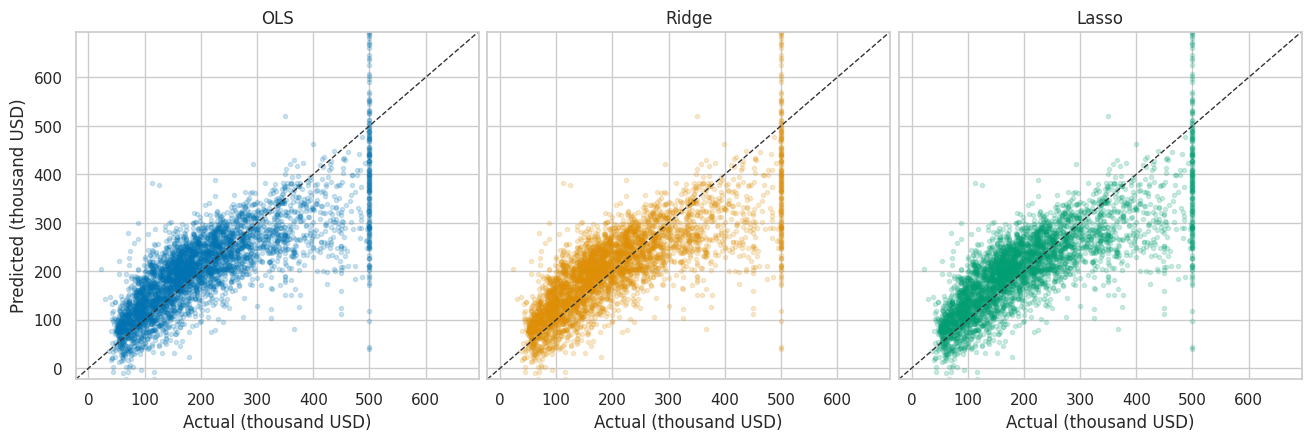

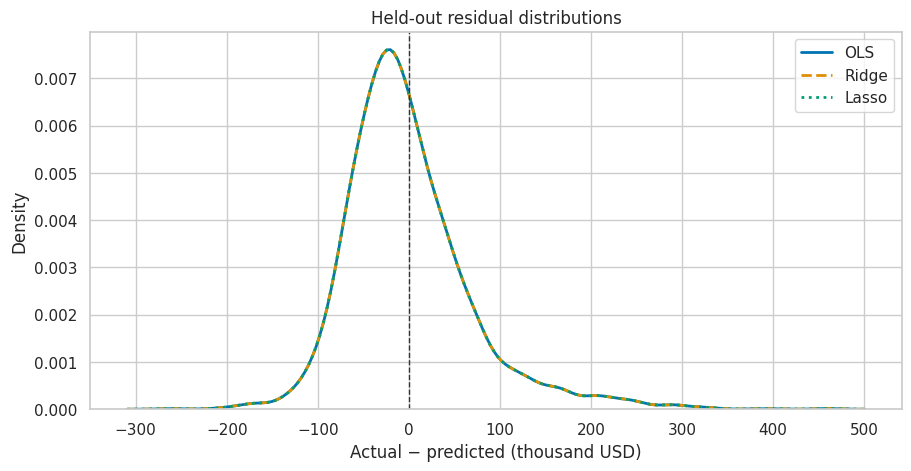

In [5]:
palette = dict(zip(predictions, sns.color_palette("colorblind", len(predictions))))
bounds = np.array([min(y_test.min(), *(p.min() for p in predictions.values())),
                   max(y_test.max(), *(p.max() for p in predictions.values()))]) / 1000

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), sharex=True, sharey=True, layout="constrained")
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test / 1000, pred / 1000, color=palette[name], alpha=0.19, s=9)
    ax.plot(bounds, bounds, "--", color="#333333", linewidth=1)
    ax.set(title=name, xlabel="Actual (thousand USD)", xlim=bounds, ylim=bounds)
axes[0].set_ylabel("Predicted (thousand USD)")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
for (name, pred), style in zip(predictions.items(), ["-", "--", ":"]):
    sns.kdeplot((y_test - pred) / 1000, ax=ax, color=palette[name],
                label=name, linestyle=style, linewidth=2)
ax.axvline(0, color="#333333", linestyle="--", linewidth=1)
ax.set(title="Held-out residual distributions", xlabel="Actual − predicted (thousand USD)",
       ylabel="Density")
ax.legend()
plt.show()

## Interpretation

**OLS** had the lowest test RMSE (69,990 USD) and an R² of 0.625. The best and worst RMSEs differ by 2 USD on this split. This result measures performance on one random holdout. Nearby block groups can be similar, so a geographic holdout would be a better test for predicting in new regions. The price cap also limits interpretation for the most expensive areas.